<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Copy_of_session4_timeseries_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Python for Data Analysis
## Session 4: Time Series & Visualization

### Agenda for today (3h)
1. The **`DatetimeIndex`** and time-based selection
2. Resampling: `resample()` for changing frequency
3. Rolling windows: `rolling()`
4. `shift()`, `pct_change()`, lagged operations
5. Visualization with **matplotlib** and **seaborn**
6. Mini-project: a one-page market dashboard

> **Data file used today**: `data/prices_long.csv`, `data/prices_wide.csv`


In [3]:
# Environment check
# Google Colab: drop `course.zip` at the ROOT of your Google Drive ("My Drive"),
#               then run this cell — it mounts your Drive and unzips for you.
# Local install: it simply verifies that data/ sits next to this notebook.
import importlib.util, os, zipfile

COURSE_ZIP_IN_DRIVE = "course.zip"

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    # No `google` package installed at all (typical local install):
    # find_spec() has to import the parent package first, so it raises here.
    IN_COLAB = False

if os.path.exists("data"):
    print("✓ data/ folder found — ready to go.")
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    zip_path = os.path.join("/content/drive/MyDrive", COURSE_ZIP_IN_DRIVE)
    if os.path.exists(zip_path):
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(".")
        print(f"✓ Extracted '{COURSE_ZIP_IN_DRIVE}' from your Drive — ready to go.")
    else:
        print(f"⚠ No archive found at: {zip_path}")
        print("  → Upload course.zip to the ROOT of your Google Drive ('My Drive'), or")
        print("    edit COURSE_ZIP_IN_DRIVE above with its path inside your Drive.")
else:
    print("⚠ data/ folder not found next to this notebook.")
    print("  → Unzip the whole course folder and start Jupyter from inside it (see SETUP.md).")


Mounted at /content/drive
✓ Extracted 'course.zip' from your Drive — ready to go.


---
## 0. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", context="notebook")


---
## 1. The `DatetimeIndex`

For time series analysis, you'll almost always want **dates as the index** of your DataFrame.
This unlocks powerful time-based operations.


In [ ]:
# Load prices in wide format -- one column per ticker
prices = pd.read_csv("data/prices_wide.csv", index_col="date", parse_dates=["date"])
prices.head()


,AAPL,MSFT,C
date,,,
2004-03-10,13.84,25.37,492.1
2004-03-11,13.58,25.09,486.2
2004-03-12,13.78,25.38,493.1
2004-03-15,13.22,25.16,491.2
2004-03-16,12.91,25.18,499.9


In [ ]:
# Notice the index dtype
print(prices.index)
print(type(prices.index))


DatetimeIndex(['2004-03-10', '2004-03-11', '2004-03-12', '2004-03-15',
               '2004-03-16', '2004-03-17', '2004-03-18', '2004-03-19',
               '2004-03-22', '2004-03-23',
               ...
               '2014-02-25', '2014-02-26', '2014-02-27', '2014-02-28',
               '2014-03-03', '2014-03-04', '2014-03-05', '2014-03-06',
               '2014-03-07', '2014-03-10'],
              dtype='datetime64[ns]', name='date', length=2517, freq=None)
<class 'pandas.core.indexes.datetimes.DatetimeIndex'>


In [ ]:
# Time-based selection
prices.loc["2008-02"].head()          # all of January 2008


,AAPL,MSFT,C
date,,,
2008-02-01,133.75,30.45,296.9
2008-02-04,131.65,30.19,292.2
2008-02-05,129.36,29.07,270.5
2008-02-06,122.00,28.52,269.2
2008-02-07,121.24,28.12,267.0


In [ ]:
prices.loc["2008-09-15":"2008-10-15"].head()   # 2008 crisis

,AAPL,MSFT,C
date,,,
2008-09-15,140.36,26.82,152.4
2008-09-16,139.88,25.99,157.5
2008-09-17,127.83,24.57,140.3
2008-09-18,134.09,25.26,166.5
2008-09-19,140.91,25.16,206.5


In [ ]:
# Useful properties of the DatetimeIndex
print("Start:", prices.index.min())
print("End:  ", prices.index.max())
print("N obs:", len(prices))
print("Day of week of first row:", prices.index[0].day_name())


Start: 2004-03-10 00:00:00
End:   2014-03-10 00:00:00
N obs: 2517
Day of week of first row: Wednesday


---
## 2. Resampling: changing frequency

`resample("freq")` groups the data into time buckets, similarly to a `groupby` but on time.

Common frequency strings:

| Code | Meaning |
|---|---|
| `"D"`  | calendar day |
| `"B"`  | business day |
| `"W"`  | weekly |
| `"M"` / `"ME"` | month end |
| `"Q"` / `"QE"` | quarter end |
| `"Y"` / `"YE"` | year end |


In [ ]:
# Monthly average closing price
monthly_avg = prices.resample("ME").mean()
monthly_avg.head()


,AAPL,MSFT,C
date,,,
2004-03-31,13.3075,24.9719,501.9812
2004-04-30,13.7624,25.9110,502.7810
2004-05-31,13.5400,25.9840,463.1400
2004-06-30,15.6648,27.3967,469.6571
2004-07-31,15.6452,28.2190,446.3238


In [ ]:
# For prices, you usually want LAST value of the period (not the mean)
monthly_close = prices.resample("ME").last()
monthly_close.head()


,AAPL,MSFT,C
date,,,
2004-03-31,13.52,24.93,517.0
2004-04-30,12.89,26.13,480.9
2004-05-31,14.03,26.23,464.3
2004-06-30,16.27,28.56,465.0
2004-07-31,16.17,28.49,440.9


In [ ]:
# OHLC bars from daily prices (useful for charts)
aapl_monthly_ohlc = prices["AAPL"].resample("ME").agg(["first", "max", "min", "last"])
aapl_monthly_ohlc.columns = ["open", "high", "low", "close"]
aapl_monthly_ohlc.head()


,open,high,low,close
date,,,,
2004-03-31,13.84,13.96,12.64,13.52
2004-04-30,13.56,14.65,12.89,12.89
2004-05-31,13.04,14.26,13.04,14.03
2004-06-30,14.03,16.85,14.03,16.27
2004-07-31,16.15,16.46,14.57,16.17


---
## 3. Rolling windows

`rolling(window=n)` creates a "moving window" view of the data — essential for moving
averages, rolling volatility, etc.


In [ ]:
# 20-day moving average of AAPL price
aapl_ma20 = prices["AAPL"].rolling(window=20).mean()
aapl_ma20.head(25)


,AAPL
date,
2004-03-10,NaN
2004-03-11,NaN
2004-03-12,NaN
2004-03-15,NaN
2004-03-16,NaN
2004-03-17,NaN
2004-03-18,NaN
2004-03-19,NaN
2004-03-22,NaN


In [ ]:
# Notice: the first 19 values are NaN (not enough data yet for a 20-day window)
# Add several moving averages to a DataFrame
aapl = pd.DataFrame({
    "close": prices["AAPL"],
    "ma_20":  prices["AAPL"].rolling(20).mean(),
    "ma_50":  prices["AAPL"].rolling(50).mean(),
    "ma_200": prices["AAPL"].rolling(200).mean(),
})
aapl.tail()


,close,ma_20,ma_50,ma_200
date,,,,
2014-03-04,531.24,528.1245,536.4230,494.2966
2014-03-05,532.36,529.3030,536.1810,494.7921
2014-03-06,530.75,530.2110,535.8156,495.2312
2014-03-07,530.44,531.1075,535.0226,495.6851
2014-03-10,530.92,531.6695,534.2876,496.1329


---
## 4. `shift` and `pct_change`: lagged operations

- **`.shift(n)`** — shift the values **forward** by `n` periods (`n` can be negative)
- **`.pct_change()`** — `(x_t - x_{t-1}) / x_{t-1}` (i.e. percent change vs. previous row)
- **`.diff()`** — `x_t - x_{t-1}` (absolute change)


In [ ]:
# Comparison: today's price, yesterday's price, daily return
demo = pd.DataFrame({
    "close":      prices["AAPL"],
    "lag1":       prices["AAPL"].shift(1),
    "diff":       prices["AAPL"].diff(),
    "pct_change": prices["AAPL"].pct_change(),
})
demo.head()


,close,lag1,diff,pct_change
date,,,,
2004-03-10,13.84,NaN,NaN,NaN
2004-03-11,13.58,13.84,-0.26,-0.0188
2004-03-12,13.78,13.58,0.20,0.0147
2004-03-15,13.22,13.78,-0.56,-0.0406
2004-03-16,12.91,13.22,-0.31,-0.0234


In [ ]:
# Daily returns for all tickers
returns = prices.pct_change().dropna()
returns.head()


,AAPL,MSFT,C
date,,,
2004-03-11,-0.0188,-0.0110,-0.0120
2004-03-12,0.0147,0.0116,0.0142
2004-03-15,-0.0406,-0.0087,-0.0039
2004-03-16,-0.0234,0.0008,0.0177
2004-03-17,0.0147,-0.0020,0.0166


In [ ]:
# Cumulative return -- "what would $1 invested at the start be worth today?"
cum_returns = (1 + returns).cumprod()
cum_returns.tail()


,AAPL,MSFT,C
date,,,
2014-03-04,38.3844,1.5140,0.0992
2014-03-05,38.4653,1.5022,0.1004
2014-03-06,38.3490,1.5037,0.1010
2014-03-07,38.3266,1.4939,0.1008
2014-03-10,38.3613,1.4907,0.1007


### Exercise 4.1
Using the `prices` DataFrame:
1. Compute the **weekly return** for each ticker (use `resample` to get weekly close, then
   `pct_change`).
2. Compute the **20-day rolling volatility** (standard deviation of daily returns) for `AAPL`.
   Multiply by `sqrt(252)` to annualize.
3. Compute the **30-day momentum** for each ticker: today's price compared to 30 trading days
   ago (`pct_change(30)`). Show the last 5 rows.


In [ ]:
# TODO: Exercise 4.1



---
## 5. Visualization with matplotlib

pandas has built-in plotting (via matplotlib): `df.plot(...)`. Great for quick exploration.
For finer control, you build plots directly with `matplotlib`.


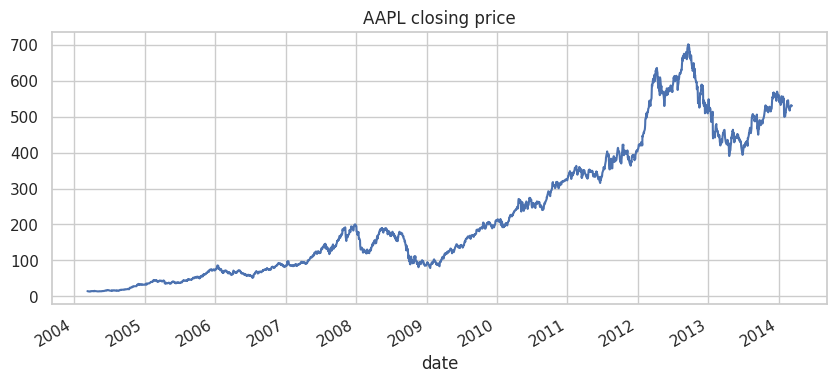

In [ ]:
# The simplest possible plot
prices["AAPL"].plot(title="AAPL closing price", figsize=(10, 4));


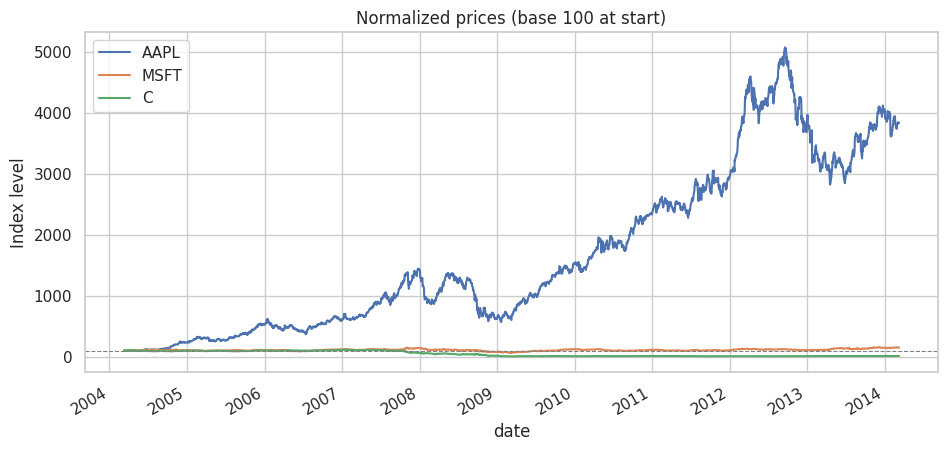

In [ ]:
# Multi-line chart -- normalize all to base 100 for comparison
normalized = prices / prices.iloc[0] * 100
ax = normalized.plot(figsize=(11, 5), title="Normalized prices (base 100 at start)")
ax.set_ylabel("Index level")
ax.axhline(100, color="gray", linestyle="--", linewidth=0.8);


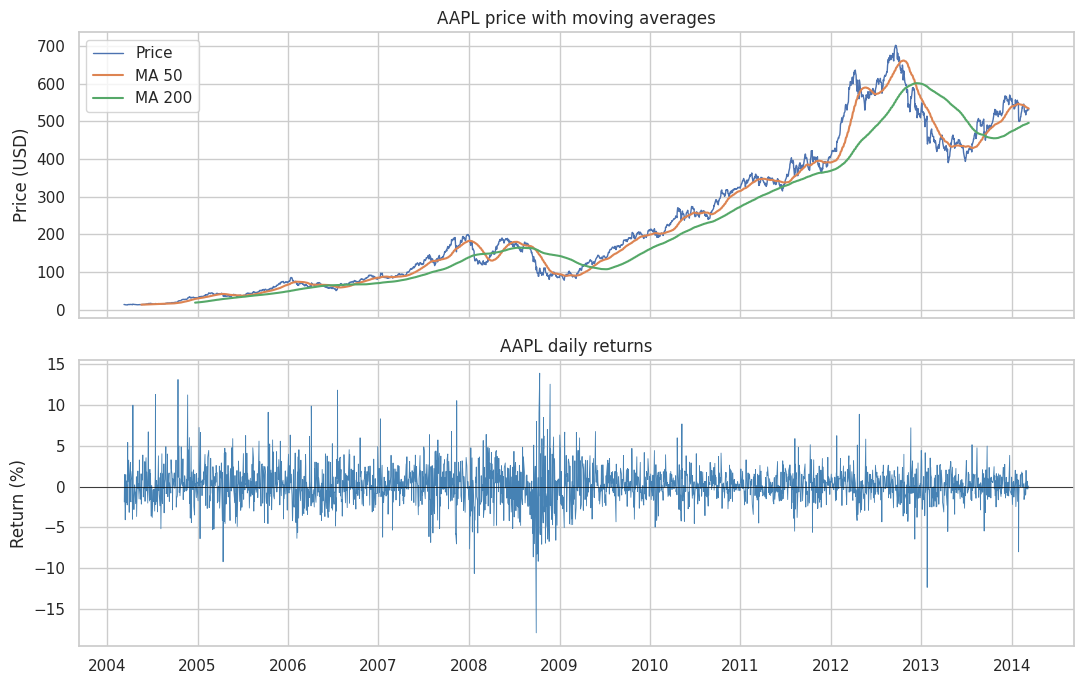

In [ ]:
# Building a more complex figure with matplotlib directly
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Top panel: price + moving averages
aapl = prices[["AAPL"]].copy()
aapl["MA50"]  = aapl["AAPL"].rolling(50).mean()
aapl["MA200"] = aapl["AAPL"].rolling(200).mean()

axes[0].plot(aapl.index, aapl["AAPL"],  label="Price",   linewidth=1)
axes[0].plot(aapl.index, aapl["MA50"],  label="MA 50",   linewidth=1.5)
axes[0].plot(aapl.index, aapl["MA200"], label="MA 200",  linewidth=1.5)
axes[0].set_title("AAPL price with moving averages")
axes[0].set_ylabel("Price (USD)")
axes[0].legend()

# Bottom panel: daily returns
daily_ret = prices["AAPL"].pct_change()
axes[1].plot(daily_ret.index, daily_ret * 100, linewidth=0.6, color="steelblue")
axes[1].axhline(0, color="black", linewidth=0.5)
axes[1].set_title("AAPL daily returns")
axes[1].set_ylabel("Return (%)")

plt.tight_layout()
plt.show()


### 5.1 Histograms and distributions


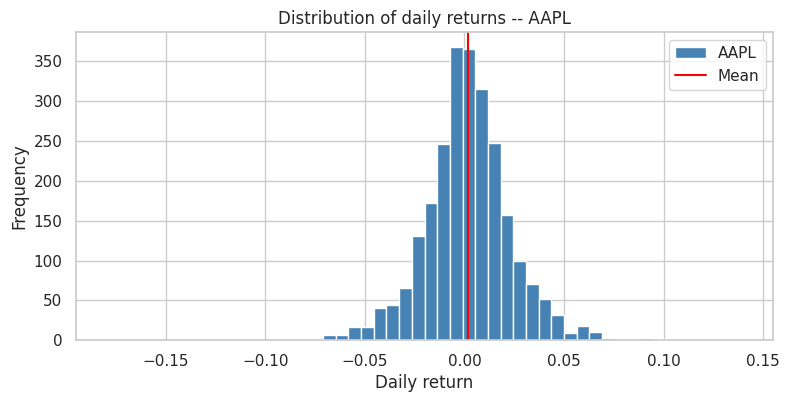

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
returns["AAPL"].plot(kind="hist", bins=50, ax=ax, color="steelblue", edgecolor="white")
ax.set_title("Distribution of daily returns -- AAPL")
ax.set_xlabel("Daily return")
ax.axvline(returns["AAPL"].mean(), color="red", label="Mean")
ax.legend();


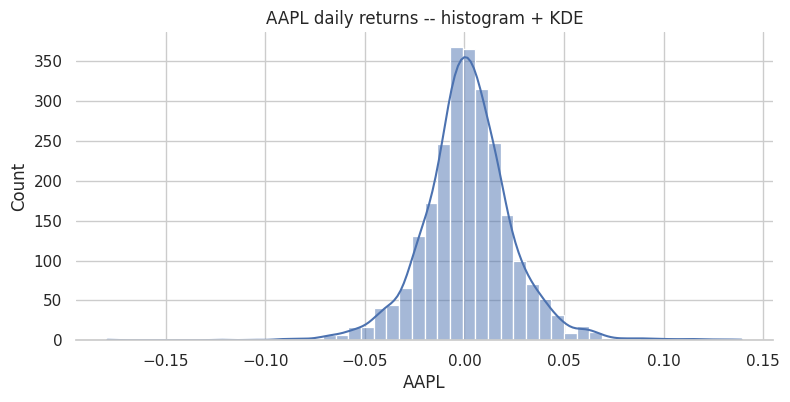

In [ ]:
# Or with seaborn for kernel-density estimate
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(returns["AAPL"], bins=50, kde=True, ax=ax)
sns.despine(left=True)
ax.set_title("AAPL daily returns -- histogram + KDE");


### 5.2 Scatter plots and pairwise comparisons


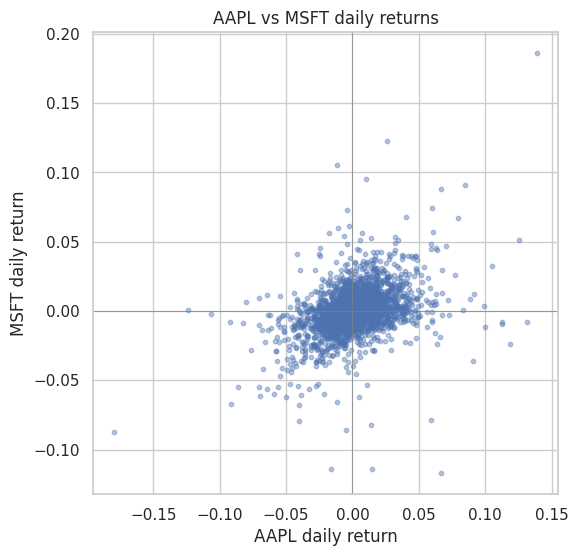

In [ ]:
# Comparing two assets
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(returns["AAPL"], returns["MSFT"], alpha=0.4, s=10)
ax.set_xlabel("AAPL daily return")
ax.set_ylabel("MSFT daily return")
ax.set_title("AAPL vs MSFT daily returns")
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5);


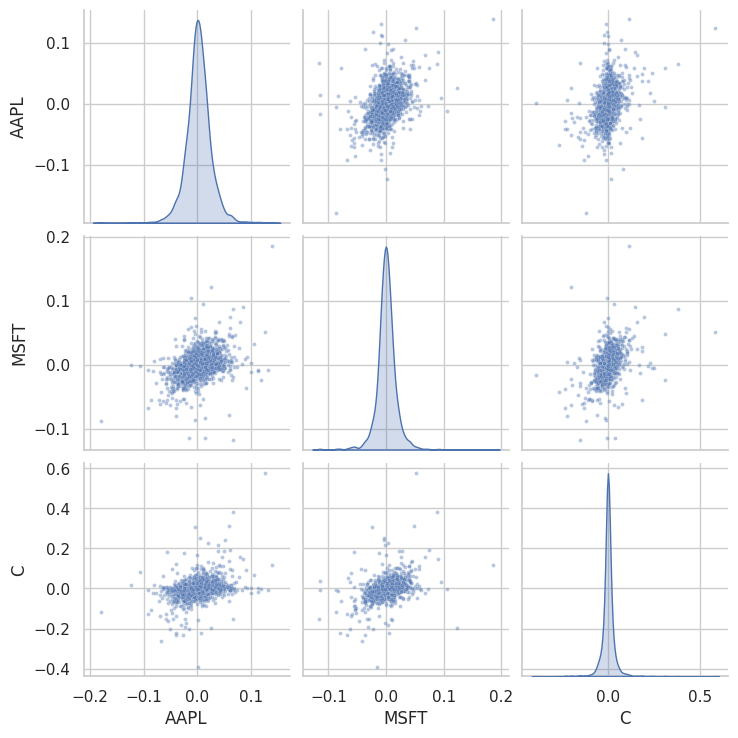

In [ ]:
# A full pair-plot is one line with seaborn
sns.pairplot(returns, plot_kws={"alpha": 0.4, "s": 8}, diag_kind="kde");


### 5.3 Correlation heatmaps


        AAPL    MSFT       C
AAPL  1.0000  0.4011  0.3275
MSFT  0.4011  1.0000  0.3966
C     0.3275  0.3966  1.0000


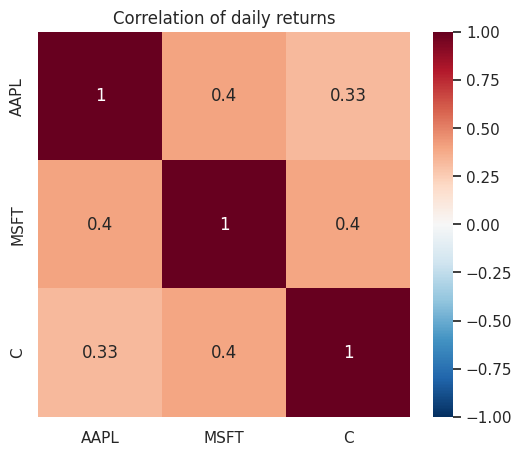

In [ ]:
corr = returns.corr()
print(corr)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of daily returns");


### Exercise 5.1
1. Plot the normalized prices (base 100) of `MSFT` and `C` on the same chart. Notice the
   dramatic divergence around 2008-2009!
2. Plot a histogram of `C` (Citigroup) daily returns, with a vertical line at the mean. The
   distribution should look very fat-tailed because of the 2008 crisis.
3. Plot a scatter of `MSFT` returns vs `C` returns. Visually, do they appear correlated?
   Confirm with `.corr()`.


In [ ]:
# TODO: Exercise 5.1



---
## 6. Mini-project: One-page market dashboard

> **Goal**: produce a clean, well-commented analysis on the **3 stocks** in `prices_wide.csv`
> (AAPL, MSFT, Citigroup) over the **2004-2014 period — including the 2008 financial crisis**.

This consolidates everything from sessions 1 to 4.

### Required deliverables

1. **Data loading & sanity checks**
   - Load `prices_wide.csv` with a `DatetimeIndex`.
   - Print: date range, number of observations, missing values per column.
   - Drop any rows containing missing values (if any).

2. **Returns table**
   - Build a `returns` DataFrame of daily returns.
   - Build a `summary` DataFrame indexed by ticker with the following annualized metrics:
     - `ann_return` = `mean_daily_return * 252`
     - `ann_vol`    = `std_daily_return * sqrt(252)`
     - `sharpe`     = `ann_return / ann_vol` (assuming risk-free rate = 0)
   - Sort by `sharpe` descending.

3. **Drawdown analysis**
   - For each ticker, compute the cumulative return series.
   - Compute the **rolling maximum** of cumulative return.
   - The **drawdown** at any point is `(cum_return - rolling_max) / rolling_max`
     (a negative number, 0 at the peaks).
   - Report the **maximum drawdown** for each ticker.

4. **Charts** (use `matplotlib` and/or `seaborn`)
   - Normalized prices (base 100) on one chart.
   - Drawdown of each ticker on one chart (filled areas look nice — use `ax.fill_between`).
   - Heatmap of the correlation matrix of returns.

5. **One-paragraph commentary**
   - Which stock has the best risk-adjusted return?
   - Which had the worst experience in 2008-2009?
   - Which pair has the lowest correlation (potentially good diversifier)?

> Use **markdown cells** to structure your work into clear sections. The reader will thank you.


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", context="notebook")

In [5]:
prices = pd.read_csv("data/prices_wide.csv", index_col="date", parse_dates=["date"])
prices

,AAPL,MSFT,C
date,,,
2004-03-10,13.84,25.37,492.10
2004-03-11,13.58,25.09,486.20
2004-03-12,13.78,25.38,493.10
2004-03-15,13.22,25.16,491.20
2004-03-16,12.91,25.18,499.90
...,...,...,...
2014-03-04,531.24,38.41,48.83
2014-03-05,532.36,38.11,49.42
2014-03-06,530.75,38.15,49.71


In [6]:
#STEP 1

# Date range
start_date = min(prices.index)
end_date = max(prices.index)
print(f"DATE RANGE:\nstart date:{start_date}\nend date:{end_date}\n")


# Number of observations
len_obs = len(prices)
print(f"no. of observations:\n{len_obs}"+"\n")


# Missing values per column
missing_value = prices.isna().sum(axis=0)
print(f"Missing value per column:\n{missing_value}")

'''
we don't have any missing values in the dataset so no imputations/deletion required.
'''

DATE RANGE:
start date:2004-03-10 00:00:00
end date:2014-03-10 00:00:00

no. of observations:
2517

Missing value per column:
AAPL    0
MSFT    0
C       0
dtype: int64


"\nwe don't have any missing values in the dataset so no imputations/deletion required.\n"

In [9]:
#STEP 2

# Building the dataframe for daily returns
returns = prices.pct_change().dropna()
print(returns.head())

ann_return = returns.mean() * 252
ann_vol = returns.std() * np.sqrt(252)
sharpe = ann_return / ann_vol

summary = pd.DataFrame(
    {
        "ann_return" : ann_return,
        "ann_vol" : ann_vol,
        "sharpe" : sharpe,
    }
)


summary = summary.sort_values('sharpe', ascending=False)
summary

# AAPL has the best sharpe ratio, whereas MSFT is the least volatile.

                AAPL      MSFT         C
date                                    
2004-03-11 -0.018786 -0.011037 -0.011989
2004-03-12  0.014728  0.011558  0.014192
2004-03-15 -0.040639 -0.008668 -0.003853
2004-03-16 -0.023449  0.000795  0.017712
2004-03-17  0.014717 -0.001986  0.016603


,ann_return,ann_vol,sharpe
AAPL,0.433523,0.369105,1.174525
MSFT,0.076932,0.272188,0.282645
C,-0.046357,0.609686,-0.076034


In [25]:
# DRAWDOWN ANALYSIS

# To calculate the cumulative return, rolling maximum
cum_ret = (1 + returns).cumprod()
rolling_max = cum_ret.cummax()
drawdown = (cum_ret - rolling_max) / rolling_max

max_drawdown = drawdown.min()
print(f"Maximum Drawdown of each ticker:\n\n{max_drawdown}")

Maximum Drawdown of each ticker:

AAPL   -0.608667
MSFT   -0.591203
C      -0.981918
dtype: float64


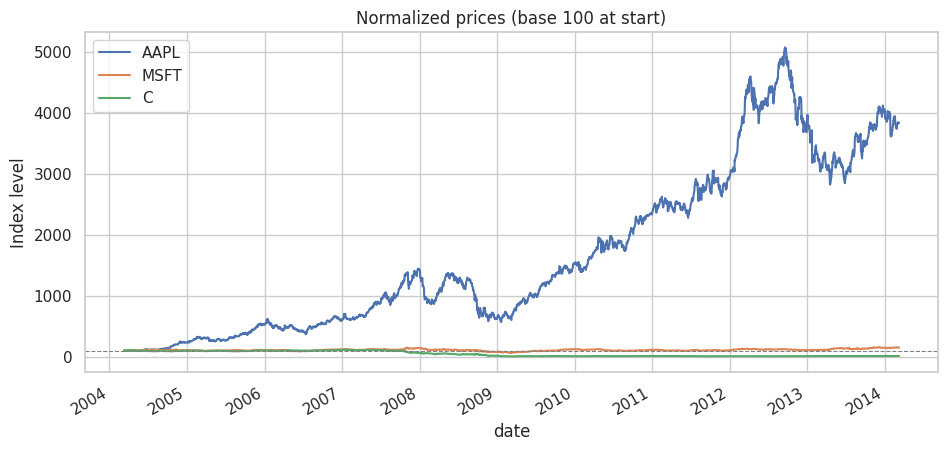

In [40]:
# Charting Normalizing the prices to base 100

Normalized_prices = prices / prices.iloc[0] * 100

ax = Normalized_prices.plot(figsize=(11, 5), title="Normalized prices (base 100 at start)")
ax.set_ylabel("Index level")
ax.axhline(100, color="gray", linestyle="--", linewidth=0.8);

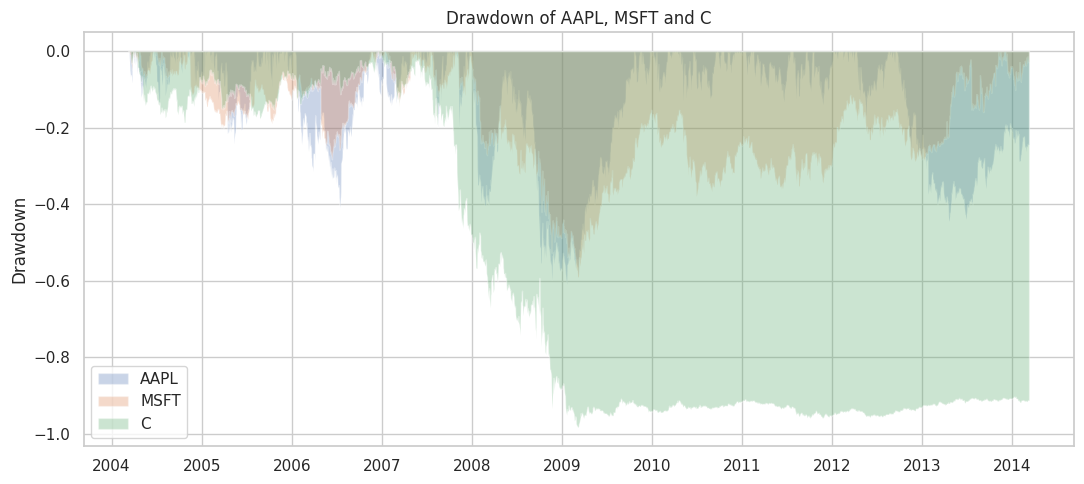

In [46]:
# Plot drawdowns
fig, ax = plt.subplots(figsize=(11, 5))

for ticker in drawdown.columns:
    ax.fill_between(drawdown.index, drawdown[ticker], 0, alpha=0.3, label=ticker)

ax.set_title("Drawdown of AAPL, MSFT and C")
ax.set_ylabel("Drawdown")
ax.legend()

plt.tight_layout()
plt.show()


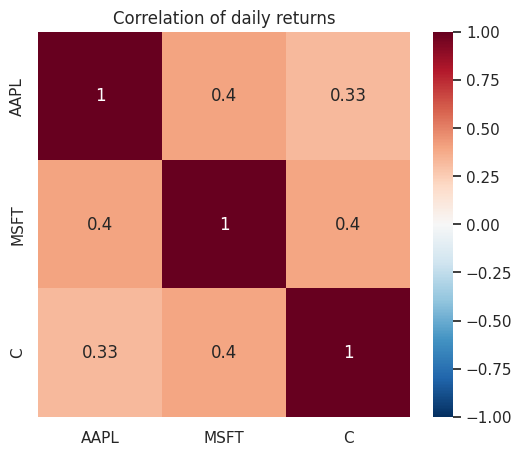

In [48]:
# Correlation matrix

corr = returns.corr()

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of daily returns");


Over the 2004–2014 period, Apple (AAPL) had the best risk-adjusted return, with an annualized return of 43.35% and a Sharpe ratio of 1.17, compared to 0.28 for Microsoft and -0.08 for Citigroup.

Citigroup (C) was the most severely affected by the 2008–2009 financial crisis, with the highest annualized volatility (60.97%) and a maximum drawdown of -98.19% over the period.

Finally, Apple and Citigroup had the lowest correlation (0.33), suggesting that combining these two stocks could offer some diversification benefits, although both remain positively correlated.
